# 07 · MLOps ve MLflow

Bir modelin hangi deneyden geldiğini, hangi sürümünün doğrulandığını ve yeni girdilerin eğitim verisinden ne ölçüde ayrıldığını izliyoruz. [Türkçe rehber](../docs/mlops_guide.md)

## 1. Yerel Tracking Server'a bağlanma

Deney verileri SQLite'ta, grafikler ve model kopyası yerel artifact alanında tutulur. Sunucuya yalnızca localhost üzerinden erişilir.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from mlflow import MlflowClient

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from mlops.tracking import EXPERIMENT, TRACKING_URI, import_runs
from mlops.register_model import register_pipeline
from mlops.monitoring import compare_distributions, load_monitoring_data

client = MlflowClient(tracking_uri=TRACKING_URI, registry_uri=TRACKING_URI)
print(TRACKING_URI)

http://127.0.0.1:5000


## 2. Geçmiş sonuçları içe aktarma

Bir run tek bir değerlendirme kaydıdır. Parametreler modelin ayarlarını, metrikler ölçülmüş sonuçları, artifact'ler ise CSV ve grafik gibi dosyaları içerir. Yedi çapraz doğrulama run'ı ile XGBoost bağımsız testi ayrı yazılır. Aynı veri ve ayarlar yeniden aktarılırsa run kimlikleri korunur.

In [2]:
runs = import_runs()
assert runs == import_runs()
rows = []
for (name, split), run_id in runs.items():
    run = client.get_run(run_id)
    metric = "average_precision_mean" if split == "cross_validation" else "average_precision"
    rows.append(dict(model=name, evaluation=split, average_precision=run.data.metrics[metric],
                     origin=run.data.tags["origin"]))
display(pd.DataFrame(rows))

,model,evaluation,average_precision,origin
0,XGBoost,cross_validation,0.764329,imported
1,Random Forest,cross_validation,0.751467,imported
2,MLP,cross_validation,0.675942,imported
3,SVM,cross_validation,0.644201,imported
4,Logistic Regression,cross_validation,0.434129,imported
5,Decision Tree,cross_validation,0.393448,imported
6,Dummy Classifier,cross_validation,0.033875,imported
7,XGBoost,independent_test,0.842887,imported


## 3. Model Registry ve sürüm doğrulaması

Model Registry modelin geçmişini ve bulunabilir sürümlerini saklar. Var olan XGBoost Pipeline'ı kaydedip geri yüklüyoruz. Sınıflar ve skorlar 8.000 eğitim örneğinde eşleşirse sürüm verified alias'ını alır. Eğitim tekrarlanmaz ve FastAPI kendi model dosyasını kullanmaya devam eder.

In [3]:
registered = register_pipeline()
print(f"{registered.name} v{registered.version} | kaynak {registered.tags['deployment_model_version']}")
print(f"Parite: {registered.tags['parity_rows']} satır | {registered.tags['verification']}")

IndustryPulse-XGBoost v1 | kaynak 1.0.0
Parite: 8000 satır | verified


## 4. Etiketsiz sensör olaylarında Data Drift

Data Drift, girdilerin dağılımının değişmesidir. Sayısal kolonlarda KS istatistiği, ürün tipinde toplam varyasyon uzaklığı kullanıyoruz. Her ikisi 0–1 aralığındadır. Eşikler inceleme başlatmak için öğretici örneklerdir. 30'dan az geçerli olay varsa karşılaştırma puanı verilmez. Canlı arıza etiketi bulunmadığından Accuracy, Recall veya Concept Drift ölçmüyoruz.

In [4]:
reference, recent = load_monitoring_data()
report = compare_distributions(reference, recent)
print(f"Referans: {report['reference_rows']} | Akış: {report['stream_rows']}")
display(pd.DataFrame(report["features"]).round(4))

Referans: 8000 | Akış: 100


,feature,method,threshold,score,status,missing_or_nonfinite,out_of_domain,outside_reference_range,valid_stream_rows
0,Air temperature [K],KS statistic,0.20,0.6108,review,0,0,0.0,100
1,Process temperature [K],KS statistic,0.20,0.6039,review,0,0,0.0,100
2,Rotational speed [rpm],KS statistic,0.20,0.0849,below_threshold,0,0,0.0,100
3,Torque [Nm],KS statistic,0.20,0.0711,below_threshold,0,0,0.0,100
4,Tool wear [min],KS statistic,0.20,0.1556,below_threshold,0,0,0.0,100
5,Type,Total variation,0.15,0.0306,below_threshold,0,0,NaN,100


## 5. Dağılımları görselleştirme

Histogram alanları örnek sayısından bağımsız karşılaştırma sağlar. Akış ilk sentetik satırların tekrarından geldiği için tork veya sıcaklık dağılımı değişebilir. Bu fark, gerçek bir fabrikanın koşullarının değiştiğini göstermez.

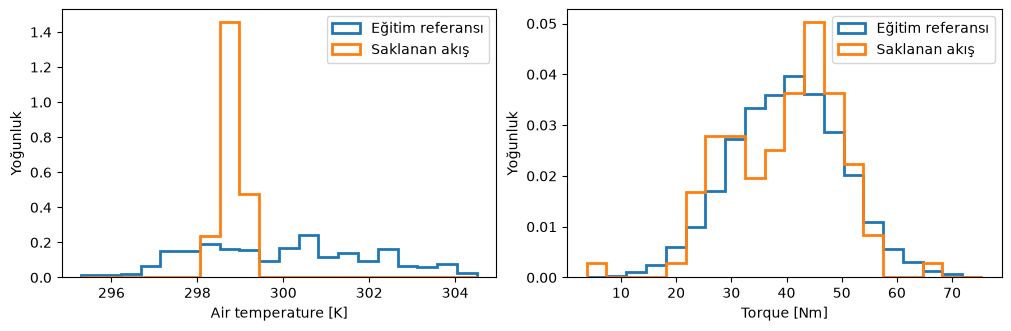

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), layout="constrained")
for ax, column in zip(axes, ["Air temperature [K]", "Torque [Nm]"]):
    bins = pd.concat([reference[column], recent[column]]).dropna()
    ax.hist(reference[column], bins=20, range=(bins.min(), bins.max()), density=True,
            histtype="step", linewidth=2, label="Eğitim referansı")
    if not recent.empty:
        ax.hist(recent[column], bins=20, range=(bins.min(), bins.max()), density=True,
                histtype="step", linewidth=2, label="Saklanan akış")
    ax.set(xlabel=column, ylabel="Yoğunluk")
    ax.legend()
plt.show()